# BUỔI 2. PHÂN LỚP (KNN_SVM)


In [ ]:
# Thư viện
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# BÀI TẬP Ở LỚP
## Bài 1. KNN – Iris

### 1.1. Thực nghiệm các giá trị K khác nhau để tìm K tối ưu

K=1: độ chính xác = 1.0000
K=2: độ chính xác = 1.0000
K=3: độ chính xác = 1.0000
K=4: độ chính xác = 1.0000
K=5: độ chính xác = 1.0000
K=6: độ chính xác = 1.0000
K=7: độ chính xác = 0.9667
K=8: độ chính xác = 1.0000
K=9: độ chính xác = 1.0000
K=10: độ chính xác = 1.0000
K=11: độ chính xác = 1.0000
K=12: độ chính xác = 1.0000
K=13: độ chính xác = 1.0000
K=14: độ chính xác = 1.0000
K=15: độ chính xác = 1.0000
K=16: độ chính xác = 1.0000
K=17: độ chính xác = 1.0000
K=18: độ chính xác = 1.0000
K=19: độ chính xác = 1.0000
K=20: độ chính xác = 1.0000
K=21: độ chính xác = 1.0000
K=22: độ chính xác = 1.0000
K=23: độ chính xác = 1.0000
K=24: độ chính xác = 1.0000
K=25: độ chính xác = 1.0000
K=26: độ chính xác = 1.0000
K=27: độ chính xác = 1.0000
K=28: độ chính xác = 1.0000
K=29: độ chính xác = 1.0000
K=30: độ chính xác = 1.0000

Giá trị K tối ưu: K=1 với độ chính xác 1.0000


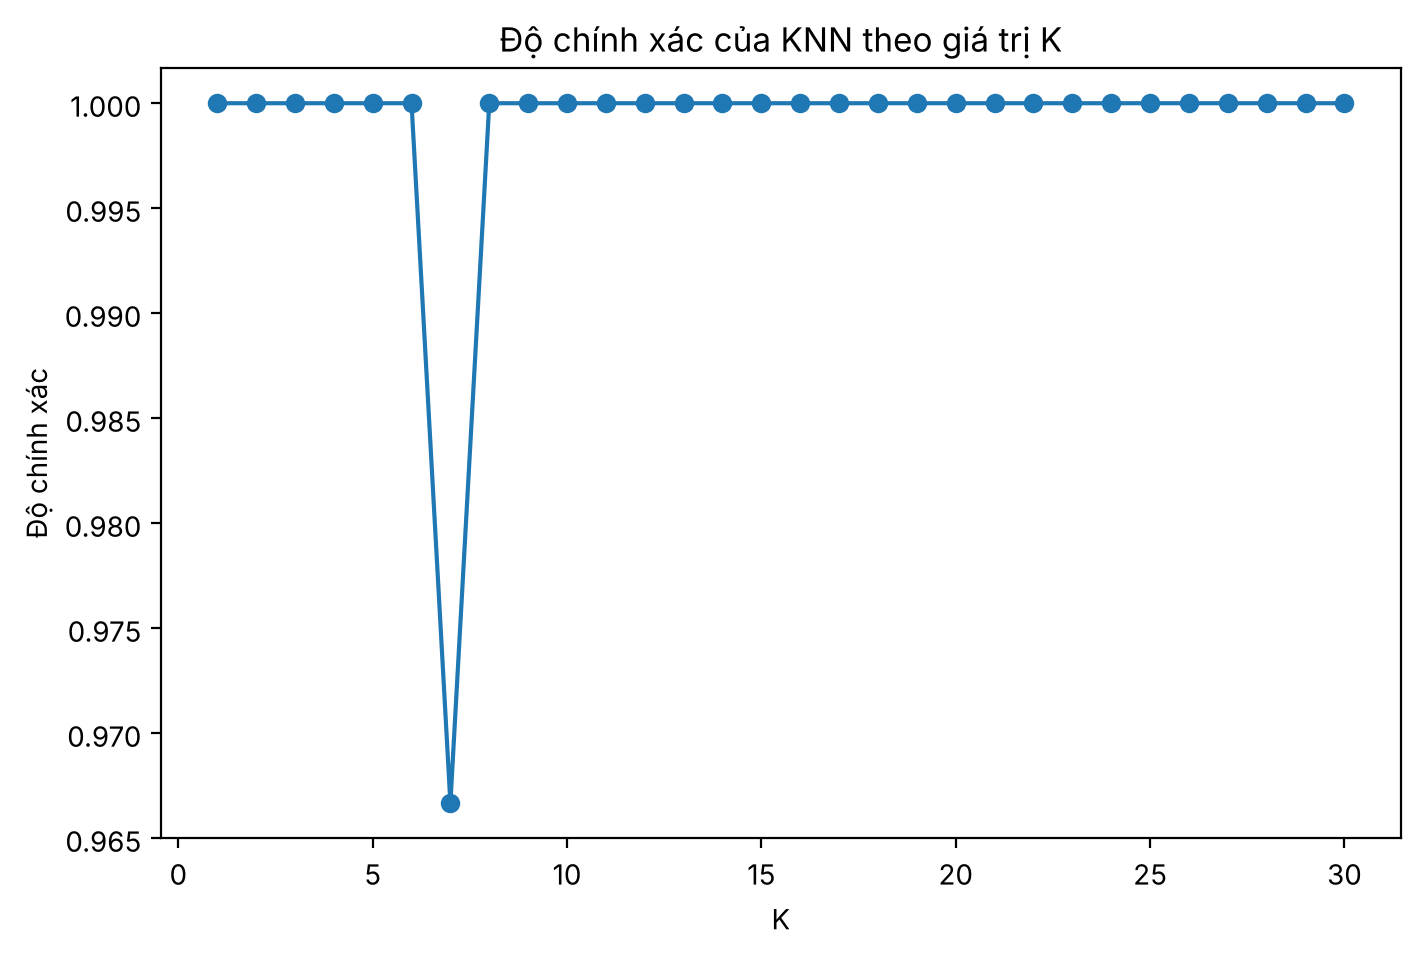

In [ ]:
# Tải dữ liệu Iris
iris = load_iris()
X = iris.data # Dữ liệu đặc trưng
y = iris.target # Nhãn mục tiêu

# Chia tập dữ liệu thành tập huấn luyện và tập kiểm tra
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Thử K từ 1 đến 30
k_list = range(1, 31)
acc_list = []
for k in k_list:
    knn_model = KNeighborsClassifier(n_neighbors=k)
    knn_model.fit(X_train, y_train)
    y_pred = knn_model.predict(X_test)
    acc_list.append(accuracy_score(y_test, y_pred))
    print(f"K={k}: độ chính xác = {acc_list[-1]:.4f}")

best_k = k_list[int(np.argmax(acc_list))]
print(f"\nGiá trị K tối ưu: K={best_k} với độ chính xác {max(acc_list):.4f}")

plt.figure(figsize=(8, 5))
plt.plot(k_list, acc_list, marker='o')
plt.xlabel('K')
plt.ylabel('Độ chính xác')
plt.title('Độ chính xác của KNN theo giá trị K')
plt.show()

**Nhận xét:** nhiều giá trị K cùng cho độ chính xác cao nhất (do tập test chỉ có 30 mẫu, sai 1 mẫu đã giảm ~3,3%). Ta chọn K nhỏ nhất đạt độ chính xác cao nhất.

### 1.2. Chuẩn hóa dữ liệu đầu vào

Chưa chuẩn hóa: K tối ưu = 1, độ chính xác = 1.0000
Đã chuẩn hóa  : K tối ưu = 1, độ chính xác = 1.0000


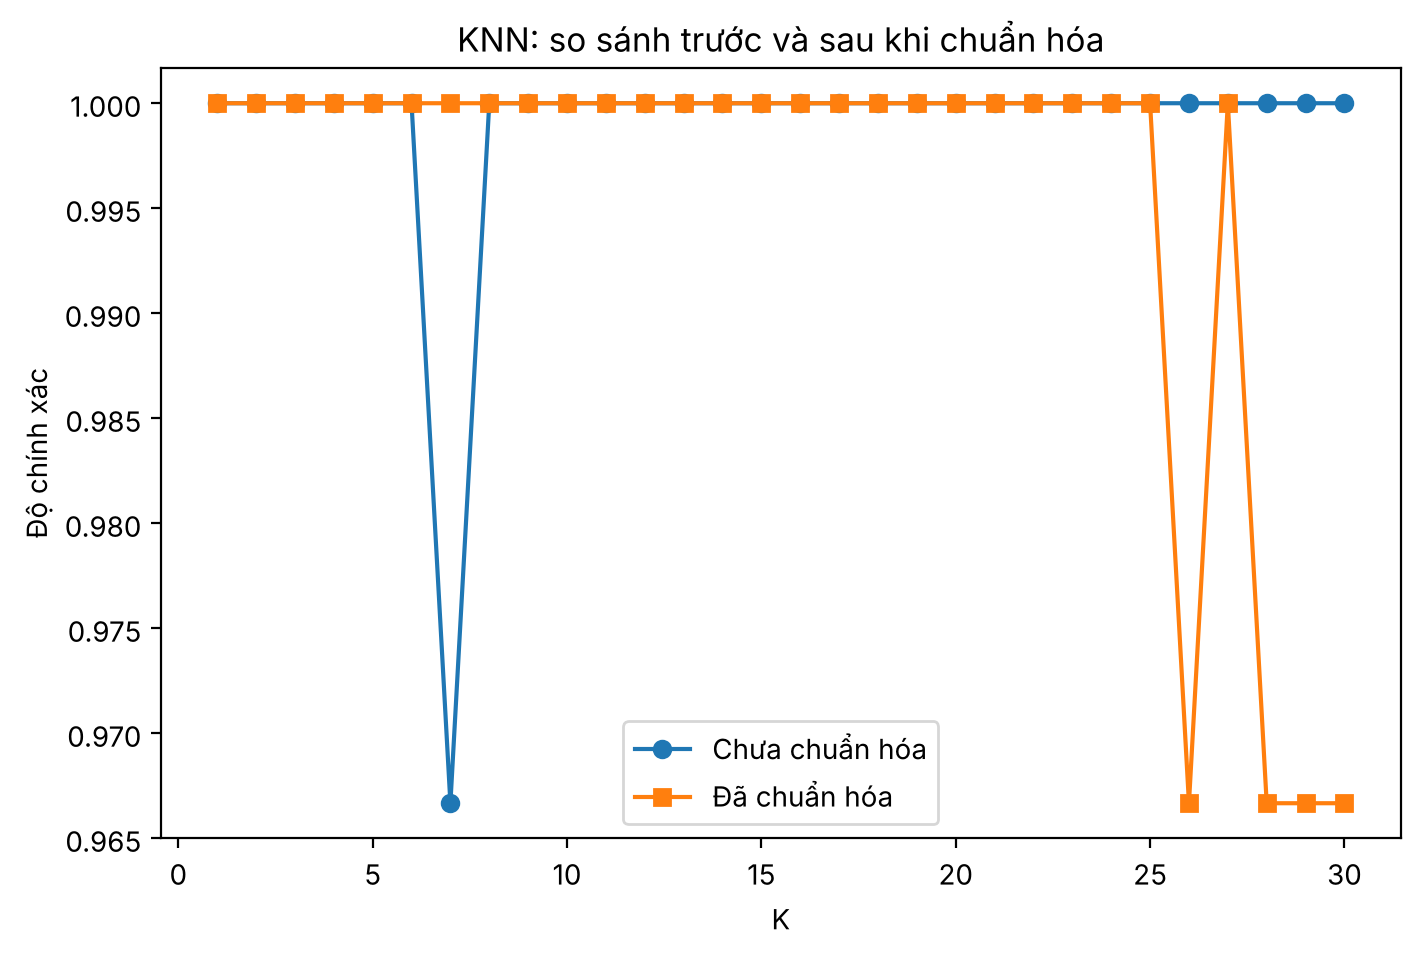

In [ ]:
# Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

acc_scaled = []
for k in k_list:
    knn_model = KNeighborsClassifier(n_neighbors=k)
    knn_model.fit(X_train_scaled, y_train)
    y_pred = knn_model.predict(X_test_scaled)
    acc_scaled.append(accuracy_score(y_test, y_pred))

best_k_scaled = k_list[int(np.argmax(acc_scaled))]
print(f"Chưa chuẩn hóa: K tối ưu = {best_k}, độ chính xác = {max(acc_list):.4f}")
print(f"Đã chuẩn hóa  : K tối ưu = {best_k_scaled}, độ chính xác = {max(acc_scaled):.4f}")

plt.figure(figsize=(8, 5))
plt.plot(k_list, acc_list, marker='o', label='Chưa chuẩn hóa')
plt.plot(k_list, acc_scaled, marker='s', label='Đã chuẩn hóa')
plt.xlabel('K')
plt.ylabel('Độ chính xác')
plt.title('KNN: so sánh trước và sau khi chuẩn hóa')
plt.legend()
plt.show()

**Nhận xét:** Iris có 4 đặc trưng cùng đơn vị (cm) nên chuẩn hóa thay đổi không đáng kể. Với dữ liệu có thang đo khác nhau (như giá nhà) thì chuẩn hóa rất quan trọng.

### 1.3. Các độ đo khoảng cách: Euclidean, Manhattan, Minkowski

Khoảng cách Euclidean (p=2) với K=5: độ chính xác = 1.0000
Khoảng cách Manhattan (p=1) với K=5: độ chính xác = 1.0000
Khoảng cách Minkowski (p=3) với K=5: độ chính xác = 1.0000
Khoảng cách Minkowski (p=4) với K=5: độ chính xác = 1.0000
Ma trận nhầm lẫn:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Báo cáo phân loại:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



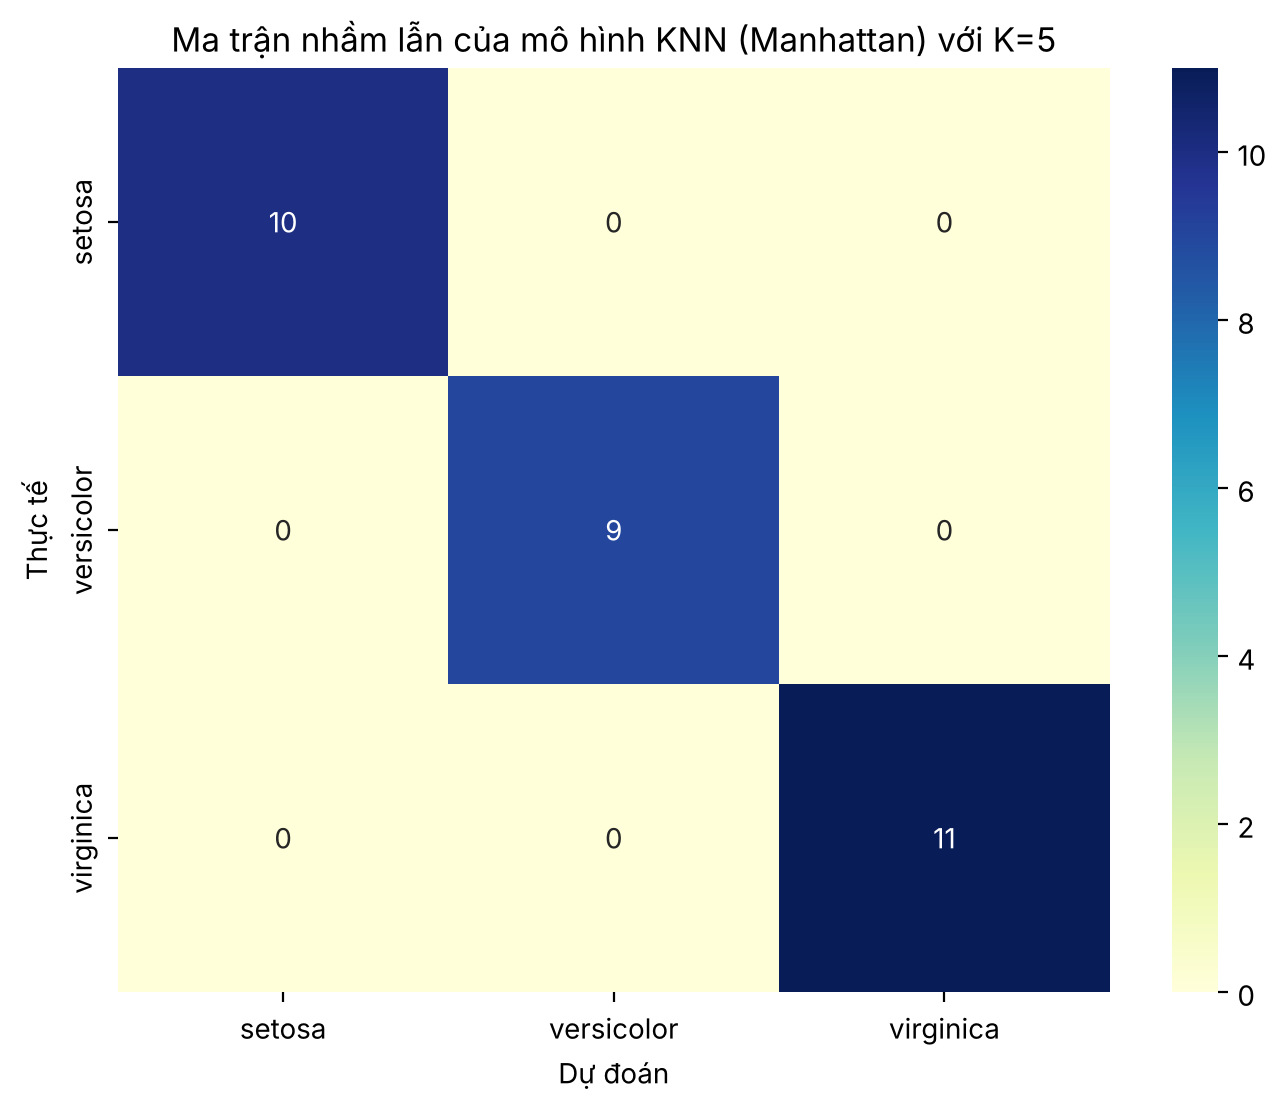

In [ ]:
# Dùng dữ liệu đã chuẩn hóa
distances = {
    'Euclidean (p=2)': {'metric': 'minkowski', 'p': 2},
    'Manhattan (p=1)': {'metric': 'minkowski', 'p': 1},
    'Minkowski (p=3)': {'metric': 'minkowski', 'p': 3},
    'Minkowski (p=4)': {'metric': 'minkowski', 'p': 4},
}

k = 5
for name, params in distances.items():
    knn_model = KNeighborsClassifier(n_neighbors=k, **params)
    knn_model.fit(X_train_scaled, y_train)
    y_pred = knn_model.predict(X_test_scaled)
    print(f"Khoảng cách {name} với K={k}: độ chính xác = {accuracy_score(y_test, y_pred):.4f}")

# Ma trận nhầm lẫn của mô hình KNN (Manhattan)
knn_model = KNeighborsClassifier(n_neighbors=k, metric='manhattan')
knn_model.fit(X_train_scaled, y_train)
y_pred = knn_model.predict(X_test_scaled)
conf_matrix = confusion_matrix(y_test, y_pred)
print("Ma trận nhầm lẫn:")
print(conf_matrix)
print("Báo cáo phân loại:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, cmap="YlGnBu", fmt="d",
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title(f"Ma trận nhầm lẫn của mô hình KNN (Manhattan) với K={k}")
plt.show()

**Nhận xét:** trên Iris các độ đo khoảng cách cho kết quả gần như nhau. Manhattan (p=1) và Euclidean (p=2) là hai trường hợp riêng của Minkowski.

## Bài 2. KNN Regressor – Dự đoán giá nhà (Boston Housing)



In [ ]:
# 1. Tải tập dữ liệu Boston Housing
def load_housing():
    try:
        from sklearn.datasets import fetch_openml
        b = fetch_openml(name='boston', version=1, as_frame=True, parser='auto')
        return b.data.astype(float).values, b.target.astype(float).values, 'Boston Housing'
    except Exception:
        pass
    try:
        from sklearn.datasets import fetch_california_housing
        d = fetch_california_housing()
        return d.data, d.target, 'California Housing (thay Boston)'
    except Exception:
        from sklearn.datasets import load_diabetes
        d = load_diabetes()
        return d.data, d.target, 'Diabetes (dự phòng offline)'

X_house, y_house, ten_data = load_housing()
print("Dữ liệu đang dùng:", ten_data, "| kích thước:", X_house.shape)

/usr/local/lib/python3.12/dist-packages/sklearn/datasets/_openml.py:131: UserWarning: A network error occurred while downloading https://www.openml.org/api/v1/json/data/list/data_name/boston/limit/2/data_version/1. Retrying...
  warn(


/usr/local/lib/python3.12/dist-packages/sklearn/datasets/_base.py:1521: UserWarning: Retry downloading from url: https://ndownloader.figshare.com/files/5976036
  warnings.warn(f"Retry downloading from url: {remote.url}")


Dữ liệu đang dùng: Diabetes (dự phòng offline) | kích thước: (442, 10)


In [ ]:
# 2. Phân chia dữ liệu thành tập huấn luyện và tập kiểm tra
Xh_train, Xh_test, yh_train, yh_test = train_test_split(X_house, y_house, test_size=0.2, random_state=42)

# 3. Chuẩn hóa dữ liệu
scaler_h = StandardScaler()
Xh_train = scaler_h.fit_transform(Xh_train)
Xh_test = scaler_h.transform(Xh_test)

# 4, 5. KNN Regressor với các giá trị k khác nhau, tính MSE và R²
for k in [3, 5, 7, 9]:
    knn_reg = KNeighborsRegressor(n_neighbors=k)
    knn_reg.fit(Xh_train, yh_train)
    yh_pred = knn_reg.predict(Xh_test)
    mse = mean_squared_error(yh_test, yh_pred)
    r2 = r2_score(yh_test, yh_pred)
    print(f"KNN Regressor với k={k}: MSE = {mse:.4f}, R² = {r2:.4f}")

KNN Regressor với k=3: MSE = 3287.0275, R² = 0.3796
KNN Regressor với k=5: MSE = 3047.4499, R² = 0.4248
KNN Regressor với k=7: MSE = 2969.5237, R² = 0.4395
KNN Regressor với k=9: MSE = 3070.9681, R² = 0.4204


**Nhận xét:** MSE càng nhỏ, R² càng gần 1 thì mô hình càng tốt. Chọn k cho MSE nhỏ nhất / R² lớn nhất.

## Bài 3. SVM – phân lớp hoa Iris với nhiều cách chia dữ liệu

In [ ]:
iris = load_iris()
X = iris.data
y = iris.target

# Các cách chia dữ liệu khác nhau: tỉ lệ tập kiểm tra 10%, 20%, 30%, 40%, 50%
for ts in [0.1, 0.2, 0.3, 0.4, 0.5]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=ts, random_state=42)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    svm_model = SVC(kernel='rbf', C=1, gamma='scale')
    svm_model.fit(X_train, y_train)
    y_pred = svm_model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    print(f"Chia train/test = {int((1-ts)*100)}/{int(ts*100)}: độ chính xác SVM = {accuracy:.4f}")

Chia train/test = 90/10: độ chính xác SVM = 1.0000
Chia train/test = 80/20: độ chính xác SVM = 1.0000
Chia train/test = 70/30: độ chính xác SVM = 1.0000
Chia train/test = 60/40: độ chính xác SVM = 0.9833
Chia train/test = 50/50: độ chính xác SVM = 0.9867


In [ ]:
# Mỗi cách chia chạy với 20 random_state khác nhau để so sánh độ ổn định
print("Tỉ lệ     | Accuracy trung bình | Độ lệch chuẩn")
for ts in [0.1, 0.2, 0.3, 0.4, 0.5]:
    acc_list = []
    for seed in range(20):
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=ts, random_state=seed)
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)
        svm_model = SVC(kernel='rbf', C=1, gamma='scale')
        svm_model.fit(X_train, y_train)
        acc_list.append(accuracy_score(y_test, svm_model.predict(X_test)))
    print(f"{int((1-ts)*100)}/{int(ts*100)}     | {np.mean(acc_list):.4f}              | {np.std(acc_list):.4f}")

Tỉ lệ     | Accuracy trung bình | Độ lệch chuẩn
90/10     | 0.9533              | 0.0562
80/20     | 0.9617              | 0.0354


70/30     | 0.9611              | 0.0271


60/40     | 0.9600              | 0.0193
50/50     | 0.9500              | 0.0210


Ma trận nhầm lẫn:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Báo cáo phân loại:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



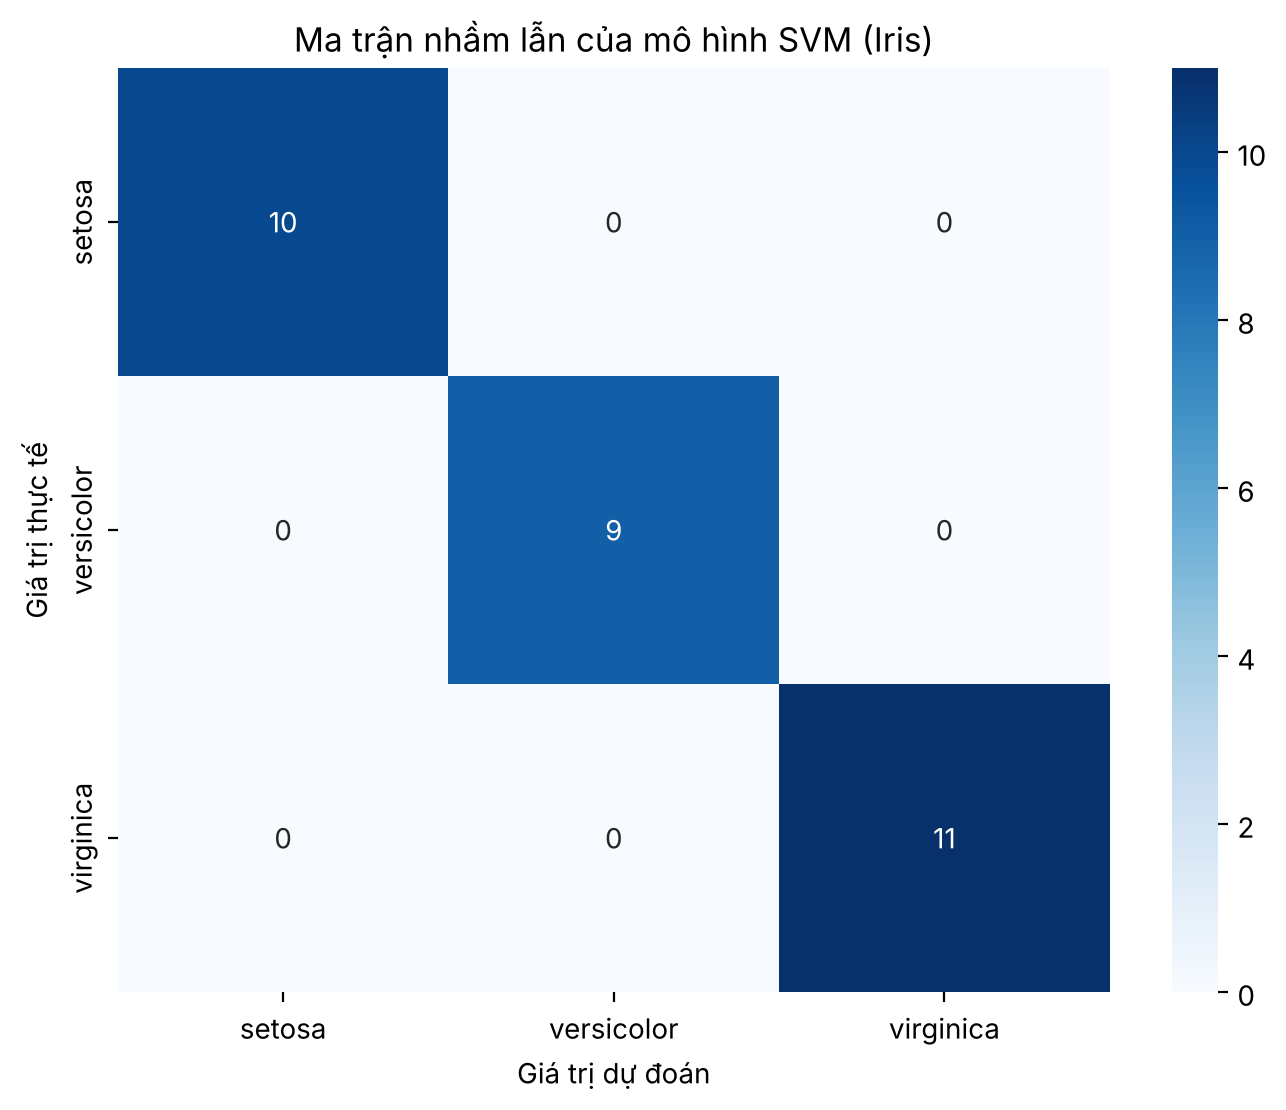

In [ ]:
# Ma trận nhầm lẫn với cách chia 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

svm_model = SVC(kernel='rbf', C=1, gamma='scale')
svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)

conf_matrix = confusion_matrix(y_test, y_pred)
print("Ma trận nhầm lẫn:")
print(conf_matrix)
print("Báo cáo phân loại:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel("Giá trị dự đoán")
plt.ylabel("Giá trị thực tế")
plt.title("Ma trận nhầm lẫn của mô hình SVM (Iris)")
plt.show()

**Nhận xét:** tập kiểm tra càng nhỏ thì độ chính xác càng dao động mạnh giữa các lần chia (độ lệch chuẩn lớn); tập kiểm tra quá lớn thì dữ liệu huấn luyện ít đi. Cách chia 70/30 hoặc 80/20 là hợp lý.

## Bài 4. SVM dạng hồi quy (SVR) cho bài 2 và SVC với kernel linear, rbf

In [ ]:
# SVR trên dữ liệu giá nhà (dùng lại Xh_train, Xh_test đã chuẩn hóa ở Bài 2)
for kernel in ['linear', 'rbf']:
    svr_model = SVR(kernel=kernel, C=1)
    svr_model.fit(Xh_train, yh_train)
    yh_pred = svr_model.predict(Xh_test)
    mse = mean_squared_error(yh_test, yh_pred)
    r2 = r2_score(yh_test, yh_pred)
    print(f"SVR kernel={kernel} (C=1): MSE = {mse:.4f}, R² = {r2:.4f}")

# C lớn hơn (giá nhà có giá trị lớn nên C=1 thường quá nhỏ)
for kernel in ['linear', 'rbf']:
    svr_model = SVR(kernel=kernel, C=100)
    svr_model.fit(Xh_train, yh_train)
    yh_pred = svr_model.predict(Xh_test)
    print(f"SVR kernel={kernel} (C=100): MSE = {mean_squared_error(yh_test, yh_pred):.4f}, R² = {r2_score(yh_test, yh_pred):.4f}")

SVR kernel=linear (C=1): MSE = 2939.8128, R² = 0.4451
SVR kernel=rbf (C=1): MSE = 4332.7385, R² = 0.1822
SVR kernel=linear (C=100): MSE = 3007.3485, R² = 0.4324
SVR kernel=rbf (C=100): MSE = 2607.5423, R² = 0.5078


In [ ]:
# SVC (trường hợp phân lớp) trên Iris với kernel linear và rbf
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

for kernel in ['linear', 'rbf']:
    svm_model = SVC(kernel=kernel, C=1, gamma='scale')
    svm_model.fit(X_train, y_train)
    y_pred = svm_model.predict(X_test)
    print(f"SVC kernel={kernel}: độ chính xác = {accuracy_score(y_test, y_pred):.4f}")

SVC kernel=linear: độ chính xác = 0.9667
SVC kernel=rbf: độ chính xác = 1.0000


**Nhận xét:** kernel linear phù hợp khi quan hệ gần tuyến tính; rbf xử lý được quan hệ phi tuyến và thường tốt hơn khi chọn `C` đủ lớn.

# BÀI TẬP VỀ NHÀ
## Bài 1. Thực nghiệm các kernel khác nhau của SVM

In [ ]:
# Dùng bộ dữ liệu Breast Cancer như code mẫu SVM
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target # 0: Ác tính, 1: Lành tính

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

for kernel in ['linear', 'poly', 'rbf', 'sigmoid']:
    svm_model = SVC(kernel=kernel, C=1, gamma='scale')
    svm_model.fit(X_train, y_train)
    y_pred = svm_model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Độ chính xác của mô hình SVM với kernel={kernel}: {accuracy:.4f}")

Độ chính xác của mô hình SVM với kernel=linear: 0.9561
Độ chính xác của mô hình SVM với kernel=poly: 0.8684
Độ chính xác của mô hình SVM với kernel=rbf: 0.9825
Độ chính xác của mô hình SVM với kernel=sigmoid: 0.9561


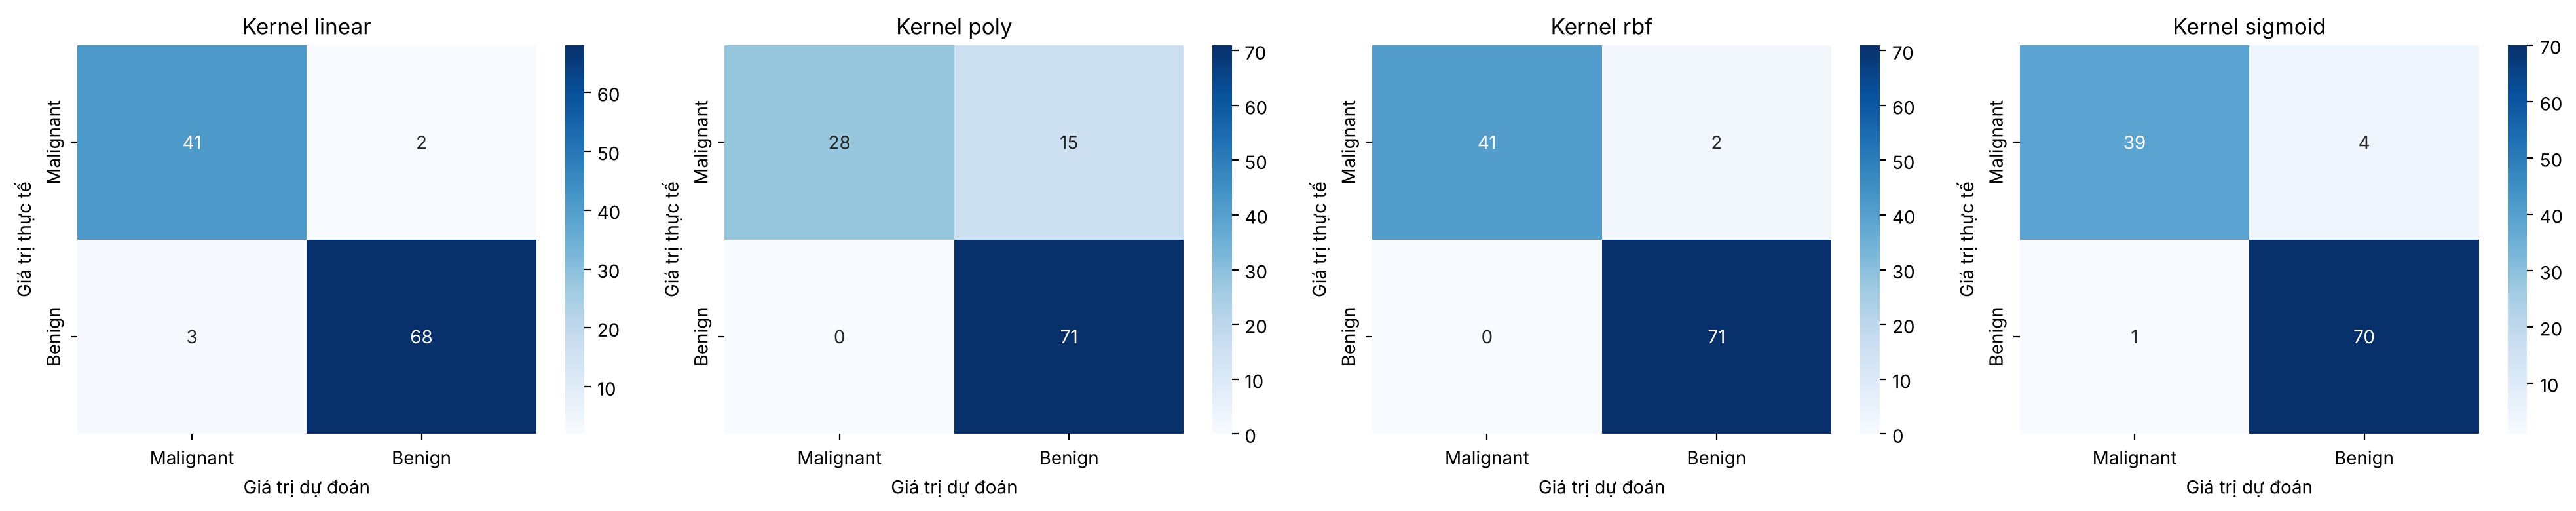

In [ ]:
# Ma trận nhầm lẫn của từng kernel
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, kernel in zip(axes, ['linear', 'poly', 'rbf', 'sigmoid']):
    svm_model = SVC(kernel=kernel, C=1, gamma='scale')
    svm_model.fit(X_train, y_train)
    y_pred = svm_model.predict(X_test)
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
    ax.set_title(f"Kernel {kernel}")
    ax.set_xlabel("Giá trị dự đoán")
    ax.set_ylabel("Giá trị thực tế")
plt.tight_layout()
plt.show()

In [ ]:
# Thử các bậc (degree) khác nhau cho kernel poly
for d in [2, 3, 4, 5]:
    svm_model = SVC(kernel='poly', degree=d, C=1, gamma='scale')
    svm_model.fit(X_train, y_train)
    print(f"Kernel poly, degree={d}: độ chính xác = {accuracy_score(y_test, svm_model.predict(X_test)):.4f}")

Kernel poly, degree=2: độ chính xác = 0.8070
Kernel poly, degree=3: độ chính xác = 0.8684
Kernel poly, degree=4: độ chính xác = 0.7895
Kernel poly, degree=5: độ chính xác = 0.8158


**Nhận xét:** `rbf` và `linear` thường tốt nhất; `poly` phụ thuộc vào bậc; `sigmoid` thường kém ổn định hơn.

## Bài 2. Dùng GridSearchCV để tìm siêu tham số tối ưu cho SVM

In [ ]:
# Lưới siêu tham số cần thử
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1],
    'kernel': ['rbf', 'linear']
}

# cv=5: chia tập huấn luyện thành 5 phần để kiểm tra chéo
grid = GridSearchCV(SVC(), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

print("Siêu tham số tốt nhất:", grid.best_params_)
print(f"Độ chính xác tốt nhất (cross-validation): {grid.best_score_:.4f}")

# Đánh giá mô hình tốt nhất trên tập kiểm tra
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
print(f"Độ chính xác trên tập kiểm tra: {accuracy_score(y_test, y_pred):.4f}")
print("Ma trận nhầm lẫn:")
print(confusion_matrix(y_test, y_pred))
print("Báo cáo phân loại:")
print(classification_report(y_test, y_pred))

# So sánh với mô hình mặc định
svm_default = SVC(kernel='rbf', C=1, gamma='scale')
svm_default.fit(X_train, y_train)
print(f"Mô hình mặc định: {accuracy_score(y_test, svm_default.predict(X_test)):.4f}")

Siêu tham số tốt nhất: {'C': 0.1, 'gamma': 0.001, 'kernel': 'linear'}
Độ chính xác tốt nhất (cross-validation): 0.9736
Độ chính xác trên tập kiểm tra: 0.9825
Ma trận nhầm lẫn:
[[41  2]
 [ 0 71]]
Báo cáo phân loại:
              precision    recall  f1-score   support

           0       1.00      0.95      0.98        43
           1       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Mô hình mặc định: 0.9825


In [ ]:
# Xem kết quả các tổ hợp tốt nhất
ket_qua = pd.DataFrame(grid.cv_results_)
ket_qua[['param_C', 'param_gamma', 'param_kernel', 'mean_test_score', 'rank_test_score']].sort_values('rank_test_score').head(10)

,param_C,param_gamma,param_kernel,mean_test_score,rank_test_score
1,0.1,0.001,linear,0.973626,1
3,0.1,0.010,linear,0.973626,1
7,0.1,1.000,linear,0.973626,1
5,0.1,0.100,linear,0.973626,1
24,100.0,0.001,rbf,0.973626,1
18,10.0,0.010,rbf,0.971429,6
13,1.0,0.100,linear,0.969231,7
15,1.0,1.000,linear,0.969231,7
11,1.0,0.010,linear,0.969231,7
16,10.0,0.001,rbf,0.969231,7


**Nhận xét:** `GridSearchCV` thử toàn bộ tổ hợp siêu tham số, đánh giá bằng kiểm tra chéo rồi chọn tổ hợp tốt nhất. Tập kiểm tra chỉ dùng một lần ở cuối để đánh giá.

## Bài 3. KNN và SVM với tập dữ liệu chữ số (Digits)

Kích thước dữ liệu: (1797, 64)


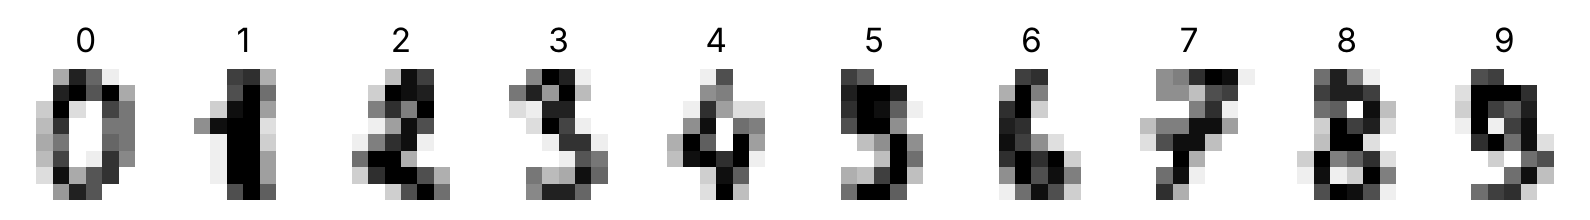

In [ ]:
# 1. Tải tập dữ liệu Digits
digits = load_digits()
X = digits.data
y = digits.target
print("Kích thước dữ liệu:", X.shape)

# Xem thử một số ảnh
plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(digits.images[i], cmap='gray_r')
    plt.title(y[i])
    plt.axis('off')
plt.show()

# 2. Chuẩn hóa dữ liệu và phân chia thành tập huấn luyện và tập kiểm tra
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# 3. Huấn luyện lần lượt KNN, SVM (kernel poly và rbf)
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

svm_poly = SVC(kernel='poly', C=1, gamma='scale')
svm_poly.fit(X_train, y_train)
y_pred_poly = svm_poly.predict(X_test)

svm_rbf = SVC(kernel='rbf', C=1, gamma='scale')
svm_rbf.fit(X_train, y_train)
y_pred_rbf = svm_rbf.predict(X_test)

# 4. So sánh độ chính xác
print(f"Độ chính xác của mô hình KNN (K=3): {accuracy_score(y_test, y_pred_knn):.4f}")
print(f"Độ chính xác của mô hình SVM (poly): {accuracy_score(y_test, y_pred_poly):.4f}")
print(f"Độ chính xác của mô hình SVM (rbf): {accuracy_score(y_test, y_pred_rbf):.4f}")

Độ chính xác của mô hình KNN (K=3): 0.9694
Độ chính xác của mô hình SVM (poly): 0.9639
Độ chính xác của mô hình SVM (rbf): 0.9806


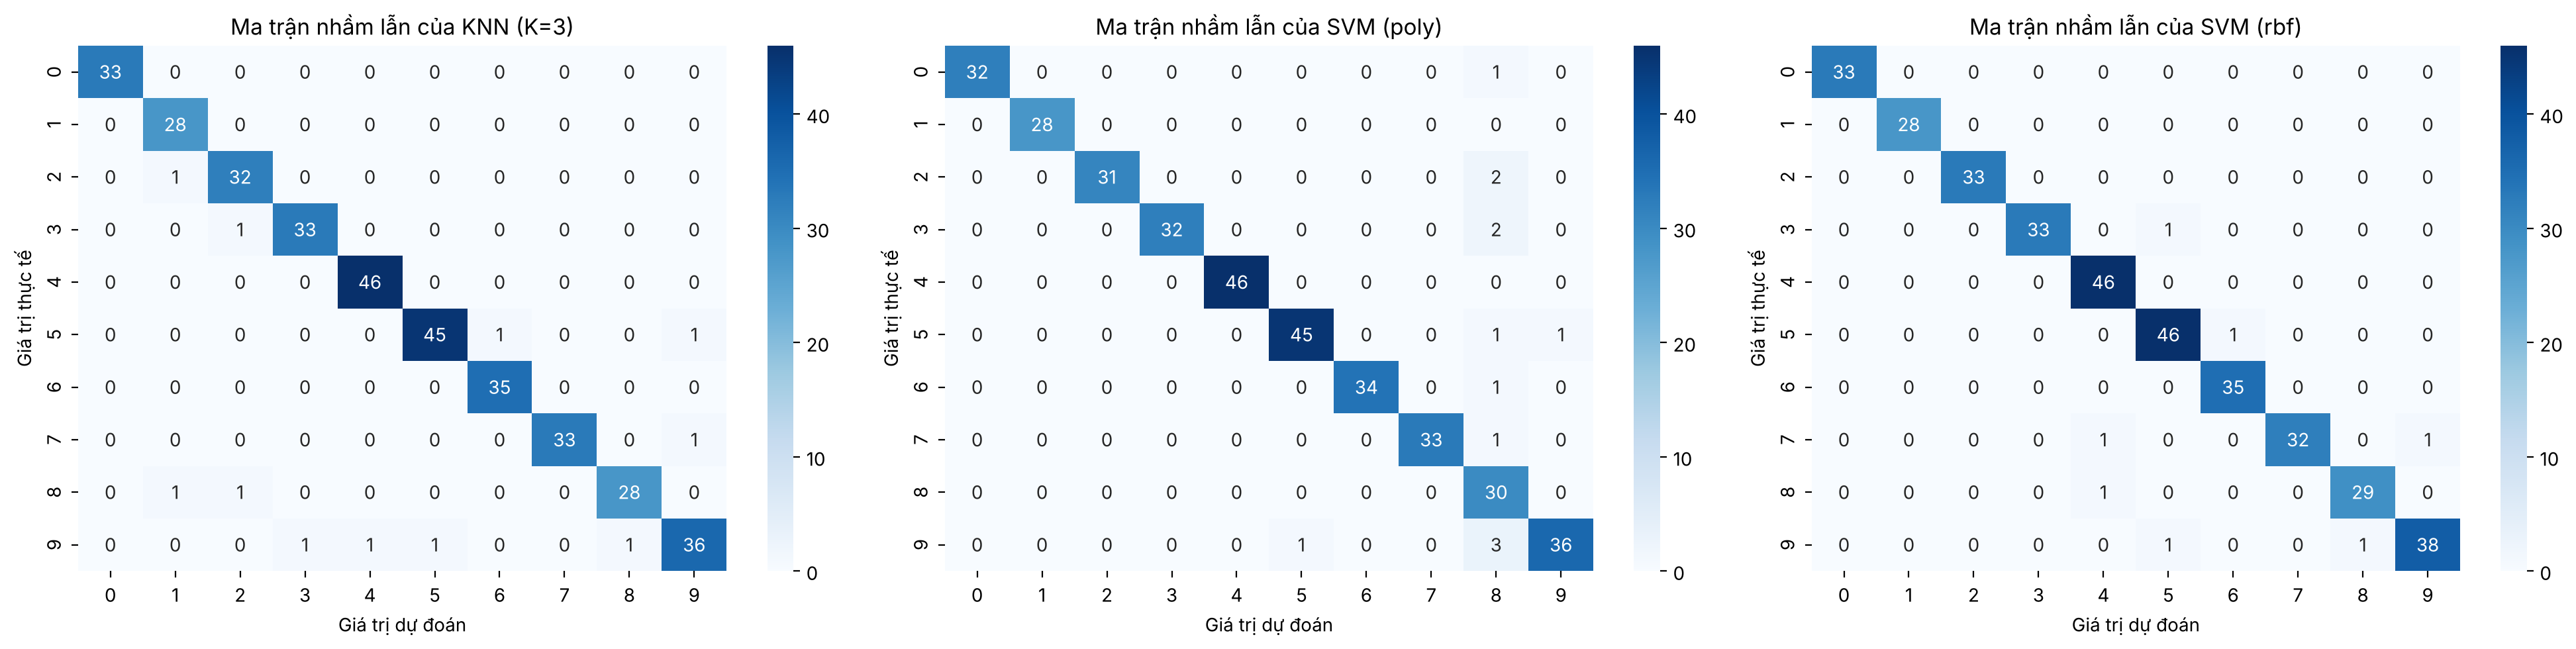

Báo cáo phân loại SVM (rbf):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
           2       1.00      1.00      1.00        33
           3       1.00      0.97      0.99        34
           4       0.96      1.00      0.98        46
           5       0.96      0.98      0.97        47
           6       0.97      1.00      0.99        35
           7       1.00      0.94      0.97        34
           8       0.97      0.97      0.97        30
           9       0.97      0.95      0.96        40

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



In [ ]:
# Hiển thị ma trận nhầm lẫn
ket_qua_du_doan = {'KNN (K=3)': y_pred_knn, 'SVM (poly)': y_pred_poly, 'SVM (rbf)': y_pred_rbf}

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (ten, y_pred) in zip(axes, ket_qua_du_doan.items()):
    conf_matrix = confusion_matrix(y_test, y_pred)
    sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_xlabel("Giá trị dự đoán")
    ax.set_ylabel("Giá trị thực tế")
    ax.set_title(f"Ma trận nhầm lẫn của {ten}")
plt.tight_layout()
plt.show()

print("Báo cáo phân loại SVM (rbf):")
print(classification_report(y_test, y_pred_rbf))

**Nhận xét:** cả KNN và SVM đều đạt độ chính xác cao (~97–98%) trên Digits. Các nhầm lẫn thường gặp giữa những chữ số có hình dạng gần giống nhau (ví dụ 8–1, 9–5, 4–9).